# Powerlifting — Pipeline GPU (Google Colab)

## Plan
| Étape | Contenu |
|---|---|
| 0 | Config, montage Google Drive, vérification GPU |
| 1 | Lecture des données |
| 2 | Feature engineering (uniquement ce qui a été validé par l'ablation locale) |
| 3 | **XGBoost** GPU (`device='cuda'`, catégorielles natives) |
| 4 | **CatBoost** GPU (`task_type='GPU'`) |
| 5 | **MLP PyTorch** avec embeddings catégoriels (GPU) |
| 6 | Blend (moindres carrés non négatifs sur les OOF) + récapitulatif |

**Historique (CV RMSE, 5-fold)** : sklearn GB 82.60 → LightGBM 78.55 → LightGBM+FE 78.36 → blend LGBM+CatBoost **77.77**

**Utilisation sur Colab**
1. Uploader le dossier `performances-en-powerlifting` (avec `train.csv`, `test.csv`) dans `MyDrive`.
2. `Exécution → Modifier le type d'exécution → GPU (T4)`.
3. `Exécution → Tout exécuter`.

Les OOF / prédictions de chaque modèle sont sauvegardés dans `outputs/` sur le Drive :
si Colab se déconnecte, relancer tout reprend là où ça s'est arrêté (les modèles déjà entraînés sont rechargés).

## 0. Configuration

In [10]:
!pip install -q catboost
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [11]:
!find /content/drive/MyDrive -name "train.csv" -not -path "*/.Trash*" 2>/dev/null

/content/drive/MyDrive/Colab Notebooks/demandes-de-pret-immobilier-aux-etats-unis/train.csv
/content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/train.csv
/content/drive/MyDrive/train.csv


In [12]:
import os, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import KFold

# ---------------- Paramètres ----------------
DRIVE_FOLDER = 'Colab Notebooks/performances-en-powerlifting'   # dossier dans MyDrive
N_FOLDS = 5
SEEDS = [42]               # ex. [42, 7, 2024] pour moyenner plusieurs seeds (plus long, souvent +0.1~0.3)
RUN = dict(xgb=True, catboost=True, mlp=True)
FORCE_RETRAIN = False      # True = ignorer les résultats sauvegardés
DEBUG = False              # True = petit échantillon, quelques itérations (test rapide du code)
# --------------------------------------------



try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = f'/content/drive/MyDrive/{DRIVE_FOLDER}'
except ImportError:
    DATA_DIR = '.'

OUT_DIR = os.path.join(DATA_DIR, 'outputs_debug' if DEBUG else 'outputs')
os.makedirs(OUT_DIR, exist_ok=True)

try:
    import torch
    GPU = torch.cuda.is_available()
except ImportError:
    GPU = False
DEVICE = 'cuda' if GPU else 'cpu'

N_EST = 100 if DEBUG else 20000   # arbres max (early stopping)
EPOCHS = 2 if DEBUG else 30       # MLP

print('DATA_DIR :', DATA_DIR)
print('OUT_DIR  :', OUT_DIR)
print('GPU      :', GPU)
assert os.path.exists(os.path.join(DATA_DIR, 'train.csv')), 'train.csv introuvable — vérifier DRIVE_FOLDER'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
DATA_DIR : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting
OUT_DIR  : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs
GPU      : True


## 1. Lecture des données

In [13]:
train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
test  = pd.read_csv(os.path.join(DATA_DIR, 'test.csv'))
if DEBUG:
    train = train.sample(3000, random_state=0).reset_index(drop=True)
    test = test.head(1000).reset_index(drop=True)

TARGET = 'TotalKg'
y = train[TARGET].values.astype(np.float64)
print('Train:', train.shape, '| Test:', test.shape)
train.head()

Train: (105000, 18) | Test: (45000, 17)


,id,Age,BodyweightKg,MeetYear,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned,TotalKg
0,27822,16.5,65.25,2016,M,Single-ply,16-17,14-18,66,Yes,Russia,Unknown,FPR,IPF,Russia,KLU,Yes,500.0
1,85202,27.0,88.50,2022,M,Raw,24-34,24-39,90,Untested,USA,IL,USPA,IPL,USA,IL,Yes,512.5
2,42217,29.5,92.30,2018,F,Raw,24-34,24-39,84+,Yes,USA,MA,USAPL,IPF,USA,MA,Yes,360.0
3,119958,27.0,52.00,2019,F,Single-ply,24-34,24-39,52,Yes,Russia,Unknown,WPC,WPC,Russia,ROS,Yes,362.5
4,37678,52.5,117.50,2025,M,Single-ply,50-54,50-59,125,Yes,USA,MI,USAPL,Unknown,USA,OH,Yes,355.0


## 2. Feature engineering

L'ablation locale (LightGBM) a montré :
- **utile** : groupe *weight class* (−0.19 RMSE)
- inutile ou nuisible : interactions Sex×Equipment, fréquences, année de naissance, target encoding (+0.27)

Les modèles GPU gèrent nativement les catégorielles → on garde le FE minimal.

In [14]:
RAW_NUM = ['Age', 'BodyweightKg', 'MeetYear']
CAT = [c for c in test.columns if test[c].dtype == 'object']

def add_features(df):
    out = df.copy()
    out['WeightClass_num'] = pd.to_numeric(out['WeightClassKg'].str.replace('+', '', regex=False), errors='coerce')
    out['Is_SHW'] = out['WeightClassKg'].str.endswith('+').astype(int)
    out['BW_minus_Class'] = out['BodyweightKg'] - out['WeightClass_num']
    return out

NUM = RAW_NUM + ['WeightClass_num', 'Is_SHW', 'BW_minus_Class']
FEATS = NUM + CAT

# Catégories construites sur train+test pour avoir les mêmes modalités
full = pd.concat([add_features(train)[FEATS], add_features(test)[FEATS]], ignore_index=True)
for c in CAT:
    full[c] = full[c].astype('category')
X  = full.iloc[:len(train)].reset_index(drop=True)
Xt = full.iloc[len(train):].reset_index(drop=True)

print(f'{len(NUM)} numériques + {len(CAT)} catégorielles = {len(FEATS)} features')
X.head()

6 numériques + 13 catégorielles = 19 features


,Age,BodyweightKg,MeetYear,WeightClass_num,Is_SHW,BW_minus_Class,Sex,Equipment,AgeClass,BirthYearClass,WeightClassKg,Tested,Country,State,Federation,ParentFederation,MeetCountry,MeetState,Sanctioned
0,16.5,65.25,2016,66.0,0,-0.75,M,Single-ply,16-17,14-18,66,Yes,Russia,Unknown,FPR,IPF,Russia,KLU,Yes
1,27.0,88.50,2022,90.0,0,-1.50,M,Raw,24-34,24-39,90,Untested,USA,IL,USPA,IPL,USA,IL,Yes
2,29.5,92.30,2018,84.0,1,8.30,F,Raw,24-34,24-39,84+,Yes,USA,MA,USAPL,IPF,USA,MA,Yes
3,27.0,52.00,2019,52.0,0,0.00,F,Single-ply,24-34,24-39,52,Yes,Russia,Unknown,WPC,WPC,Russia,ROS,Yes
4,52.5,117.50,2025,125.0,0,-7.50,M,Single-ply,50-54,50-59,125,Yes,USA,MI,USAPL,Unknown,USA,OH,Yes


## Outils communs : CV + sauvegarde/reprise

In [15]:
results = {}  # nom -> (oof, pred_test, rmse)

def rmse(a, b):
    return float(np.sqrt(np.mean((a - b) ** 2)))

def save_submission(fname, pred):
    path = os.path.join(OUT_DIR, fname)
    pd.DataFrame({'id': test['id'], TARGET: np.clip(pred, 0, None)}).to_csv(path, index=False)
    print('Soumission :', path)

def run_cv(name, fit_predict):
    """fit_predict(idx_train, idx_val, seed) -> (pred_val, pred_test)"""
    f_oof, f_pred = os.path.join(OUT_DIR, f'{name}_oof.npy'), os.path.join(OUT_DIR, f'{name}_test.npy')
    if os.path.exists(f_oof) and os.path.exists(f_pred) and not FORCE_RETRAIN:
        oof, pred = np.load(f_oof), np.load(f_pred)
        print(f'[{name}] rechargé depuis le Drive')
    else:
        oof, pred = np.zeros(len(X)), np.zeros(len(Xt))
        t0 = time.time()
        for seed in SEEDS:
            for i, (a, b) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=seed).split(X)):
                t = time.time()
                p_val, p_test = fit_predict(a, b, seed)
                oof[b] += p_val / len(SEEDS)
                pred += p_test / (N_FOLDS * len(SEEDS))
                print(f'  [{name}] seed {seed} fold {i}: RMSE {rmse(y[b], p_val):.3f}  ({time.time() - t:.0f}s)')
        print(f'  [{name}] temps total : {(time.time() - t0) / 60:.1f} min')
        np.save(f_oof, oof); np.save(f_pred, pred)
        save_submission(f'submission_gpu_{name}.csv', pred)
    results[name] = (oof, pred, rmse(y, oof))
    print(f'[{name}] CV RMSE = {results[name][2]:.3f}')

## 3. XGBoost (GPU)
`enable_categorical=True` : partitionnement optimal des catégories (pas de one-hot).

In [16]:
import xgboost as xgb
print('xgboost', xgb.__version__)

def xgb_fit(a, b, seed):
    m = xgb.XGBRegressor(
        n_estimators=N_EST, learning_rate=0.03, max_depth=8, min_child_weight=10,
        subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
        tree_method='hist', device=DEVICE, enable_categorical=True, max_cat_to_onehot=1,
        early_stopping_rounds=200, eval_metric='rmse', random_state=seed,
    )
    m.fit(X.iloc[a], y[a], eval_set=[(X.iloc[b], y[b])], verbose=False)
    return m.predict(X.iloc[b]), m.predict(Xt)

if RUN['xgb']:
    run_cv('xgb', xgb_fit)

xgboost 3.4.1
  [xgb] seed 42 fold 0: RMSE 78.889  (17s)
  [xgb] seed 42 fold 1: RMSE 79.408  (6s)
  [xgb] seed 42 fold 2: RMSE 79.282  (6s)
  [xgb] seed 42 fold 3: RMSE 79.150  (6s)
  [xgb] seed 42 fold 4: RMSE 78.252  (7s)
  [xgb] temps total : 0.7 min
Soumission : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs/submission_gpu_xgb.csv
[xgb] CV RMSE = 78.997


## 4. CatBoost (GPU)
Ordered target statistics sur les catégorielles + combinaisons automatiques de catégories.

In [17]:
from catboost import CatBoostRegressor

X_cb  = X.astype({c: str for c in CAT})
Xt_cb = Xt.astype({c: str for c in CAT})

def cat_fit(a, b, seed):
    params = dict(iterations=N_EST, learning_rate=0.05, depth=8, l2_leaf_reg=3,
                  loss_function='RMSE', od_type='Iter', od_wait=300,
                  random_seed=seed, verbose=0)
    if GPU:
        params.update(task_type='GPU', devices='0')
    m = CatBoostRegressor(**params)
    m.fit(X_cb.iloc[a], y[a], cat_features=CAT, eval_set=(X_cb.iloc[b], y[b]), use_best_model=True)
    return m.predict(X_cb.iloc[b]), m.predict(Xt_cb)

if RUN['catboost']:
    run_cv('catboost', cat_fit)

  [catboost] seed 42 fold 0: RMSE 78.655  (132s)
  [catboost] seed 42 fold 1: RMSE 78.687  (159s)
  [catboost] seed 42 fold 2: RMSE 79.133  (177s)
  [catboost] seed 42 fold 3: RMSE 78.672  (135s)
  [catboost] seed 42 fold 4: RMSE 77.831  (176s)
  [catboost] temps total : 13.0 min
Soumission : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs/submission_gpu_catboost.csv
[catboost] CV RMSE = 78.597


## 5. MLP PyTorch avec embeddings (GPU)
- Catégorielles → embeddings (modalités rares < 5 occurrences dans le train regroupées dans l'index 0)
- Numériques → NaN remplacés par la médiane + indicateur de NaN, puis standardisés
- Cible standardisée, AdamW + OneCycle, meilleure epoch sur le fold de validation

Modèle de nature très différente des arbres → surtout utile pour le **blend**.

In [18]:
import torch
import torch.nn as nn

# --- Préparation des tenseurs (une seule fois) ---
n_tr = len(X)
cat_codes, cards = [], []
for c in CAT:
    codes = full[c].cat.codes.values.astype(np.int64) + 1          # NaN -> 0
    counts = np.bincount(codes[:n_tr], minlength=codes.max() + 1)
    codes = np.where(counts[codes] >= 5, codes, 0)                  # rares -> 0
    _, codes = np.unique(codes, return_inverse=True)                 # réindexation compacte
    cat_codes.append(codes); cards.append(int(codes.max()) + 1)
XC = np.stack(cat_codes, axis=1)

num = full[NUM].astype(float)
nan_cols = [c for c in NUM if num[c].isna().any()]
num_ind = num[nan_cols].isna().astype(float).add_suffix('_nan')
num = num.fillna(num.median())
num = (num - num.mean()) / (num.std() + 1e-9)
XN = pd.concat([num, num_ind], axis=1).values.astype(np.float32)

XC_t = torch.tensor(XC, device=DEVICE)
XN_t = torch.tensor(XN, device=DEVICE)
print('Cardinalités :', dict(zip(CAT, cards)))
print('Numériques NN :', XN.shape[1])


class TabMLP(nn.Module):
    def __init__(self, cards, n_num):
        super().__init__()
        self.embs = nn.ModuleList([nn.Embedding(n, min(32, (n + 1) // 2)) for n in cards])
        d = sum(e.embedding_dim for e in self.embs) + n_num
        self.mlp = nn.Sequential(
            nn.Linear(d, 512), nn.BatchNorm1d(512), nn.SiLU(), nn.Dropout(0.15),
            nn.Linear(512, 256), nn.BatchNorm1d(256), nn.SiLU(), nn.Dropout(0.10),
            nn.Linear(256, 128), nn.SiLU(),
            nn.Linear(128, 1),
        )

    def forward(self, xc, xn):
        e = [emb(xc[:, i]) for i, emb in enumerate(self.embs)]
        return self.mlp(torch.cat(e + [xn], dim=1)).squeeze(1)


@torch.no_grad()
def nn_predict(model, idx, bs=8192):
    model.eval()
    return torch.cat([model(XC_t[idx[i:i + bs]], XN_t[idx[i:i + bs]]) for i in range(0, len(idx), bs)]).cpu().numpy()


def mlp_fit(a, b, seed, bs=1024, lr=3e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    mu, sd = y[a].mean(), y[a].std()
    y_t = torch.tensor((y - mu) / sd, dtype=torch.float32, device=DEVICE)
    a_t, b_t = torch.tensor(a, device=DEVICE), torch.tensor(b, device=DEVICE)
    test_idx = torch.arange(n_tr, len(full), device=DEVICE)

    model = TabMLP(cards, XN.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    steps_per_epoch = (len(a) + bs - 1) // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=EPOCHS * steps_per_epoch)
    loss_fn = nn.MSELoss()

    best, best_state = np.inf, None
    for ep in range(EPOCHS):
        model.train()
        perm = a_t[torch.randperm(len(a_t), device=DEVICE)]
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            if len(idx) < 2:   # BatchNorm
                sched.step(); continue
            opt.zero_grad()
            loss = loss_fn(model(XC_t[idx], XN_t[idx]), y_t[idx])
            loss.backward()
            opt.step(); sched.step()
        val = rmse(y[b], nn_predict(model, b_t) * sd + mu)
        if val < best:
            best, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return nn_predict(model, b_t) * sd + mu, nn_predict(model, test_idx) * sd + mu

if RUN['mlp']:
    run_cv('mlp', mlp_fit)

Cardinalités : {'Sex': 3, 'Equipment': 5, 'AgeClass': 19, 'BirthYearClass': 8, 'WeightClassKg': 99, 'Tested': 2, 'Country': 119, 'State': 95, 'Federation': 318, 'ParentFederation': 22, 'MeetCountry': 112, 'MeetState': 201, 'Sanctioned': 2}
Numériques NN : 8
  [mlp] seed 42 fold 0: RMSE 80.441  (17s)
  [mlp] seed 42 fold 1: RMSE 80.843  (11s)
  [mlp] seed 42 fold 2: RMSE 80.841  (10s)
  [mlp] seed 42 fold 3: RMSE 80.656  (11s)
  [mlp] seed 42 fold 4: RMSE 80.316  (11s)
  [mlp] temps total : 1.0 min
Soumission : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs/submission_gpu_mlp.csv
[mlp] CV RMSE = 80.620


## 6. Blend
Poids ≥ 0 trouvés par moindres carrés non négatifs (NNLS) sur les prédictions OOF.

In [19]:
from scipy.optimize import nnls

names = list(results)
P_oof  = np.column_stack([results[n][0] for n in names])
P_test = np.column_stack([results[n][1] for n in names])

w, _ = nnls(P_oof, y)
oof_blend, pred_blend = P_oof @ w, P_test @ w
results['blend'] = (oof_blend, pred_blend, rmse(y, oof_blend))

print('Poids :', dict(zip(names, np.round(w, 3))))
print(f'Blend CV RMSE = {results["blend"][2]:.3f}')
save_submission('submission_gpu_blend.csv', pred_blend)

Poids : {'xgb': np.float64(0.344), 'catboost': np.float64(0.499), 'mlp': np.float64(0.157)}
Blend CV RMSE = 77.775
Soumission : /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs/submission_gpu_blend.csv


Corrélation des OOF (plus c'est bas, plus le blend aide) :


,xgb,catboost,mlp
xgb,1.0000,0.9877,0.9855
catboost,0.9877,1.0000,0.9821
mlp,0.9855,0.9821,1.0000


LGBM+CatBoost local (ref)    77.770
blend                        77.775
catboost                     78.597
xgb                          78.997
mlp                          80.620
dtype: float64


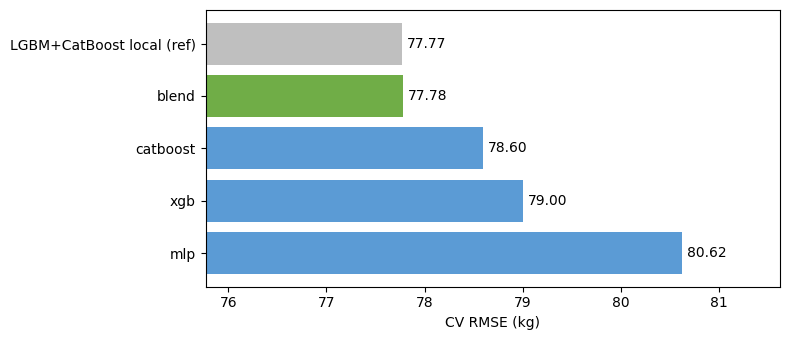


Fichiers dans /content/drive/MyDrive/Colab Notebooks/performances-en-powerlifting/outputs :
['submission_gpu_blend.csv', 'submission_gpu_catboost.csv', 'submission_gpu_mlp.csv', 'submission_gpu_xgb.csv']


In [20]:
print('Corrélation des OOF (plus c\'est bas, plus le blend aide) :')
display(pd.DataFrame(P_oof, columns=names).corr().round(4))

summary = pd.Series({'LGBM+CatBoost local (ref)': 77.77, **{k: v[2] for k, v in results.items()}}).sort_values()
print(summary.round(3))

fig, ax = plt.subplots(figsize=(8, 0.5 * len(summary) + 1))
ax.barh(summary.index, summary.values,
        color=['#70AD47' if k == 'blend' else '#BFBFBF' if 'ref' in k else '#5B9BD5' for k in summary.index])
for i, v in enumerate(summary.values):
    ax.text(v + 0.05, i, f'{v:.2f}', va='center')
ax.set_xlim(summary.min() - 2, summary.max() + 1)
ax.set_xlabel('CV RMSE (kg)')
ax.invert_yaxis()
plt.tight_layout(); plt.show()

print('\nFichiers dans', OUT_DIR, ':')
print(sorted(f for f in os.listdir(OUT_DIR) if f.endswith('.csv')))